In [2]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT = Path.cwd().parent
PROCESSED = PROJECT / "data" / "processed"
FIGS = PROJECT / "figures"
FIGS.mkdir(exist_ok=True)

df = pd.read_csv(PROCESSED / "daily_dataset.csv", index_col="date", parse_dates=True)
print(df.shape, df.index.min().date(), "to", df.index.max().date())

(2967, 35) 2015-01-02 to 2026-10-20


In [4]:
EVENTS = {
    "Ukraine invasion (2022)":          "2022-02-24",  # invasion began overnight, before US open
    "Hamas attack (Oct 2023)":          "2023-10-09",  # attack Sat 7 Oct -> Mon
    "Iran attack (Apr 2024)":           "2024-04-15",  # attack Sat 13 Apr -> Mon
    "Iran missiles (Oct 2024)":         "2024-10-01",  # launched during US trading hours
    "Israel strikes Iran (Jun 2025)":   "2025-06-13",  # strikes overnight Thu->Fri
    "US strikes Iran (Jun 2025)":       "2025-06-23",  # strikes Sat 21 Jun -> Mon
    "US-Israel war on Iran (2026)":     "2026-03-02",  # strikes Sat 28 Feb -> Mon
}

# check every day 0 is a trading day in our data
for name, d in EVENTS.items():
    print(f"{name:32s} {d}  trading day: {pd.Timestamp(d) in df.index}")

Ukraine invasion (2022)          2022-02-24  trading day: True
Hamas attack (Oct 2023)          2023-10-09  trading day: True
Iran attack (Apr 2024)           2024-04-15  trading day: True
Iran missiles (Oct 2024)         2024-10-01  trading day: True
Israel strikes Iran (Jun 2025)   2025-06-13  trading day: True
US strikes Iran (Jun 2025)       2025-06-23  trading day: True
US-Israel war on Iran (2026)     2026-03-02  trading day: True


In [5]:
def event_window(day0, pre=60, post=20):
    pos = df.index.get_loc(pd.Timestamp(day0))
    start = max(pos - pre, 0)
    w = df.iloc[start : pos + post + 1].copy()
    w["t"] = np.arange(len(w)) - (pos - start)     # t = 0 on the event day
    return w

def cum_from_day_minus1(w, col):
    """Cumulative log return (%), set to 0 on the day before the event."""
    c = w[col].fillna(0).cumsum()
    return c - c[w["t"] == -1].iloc[0]

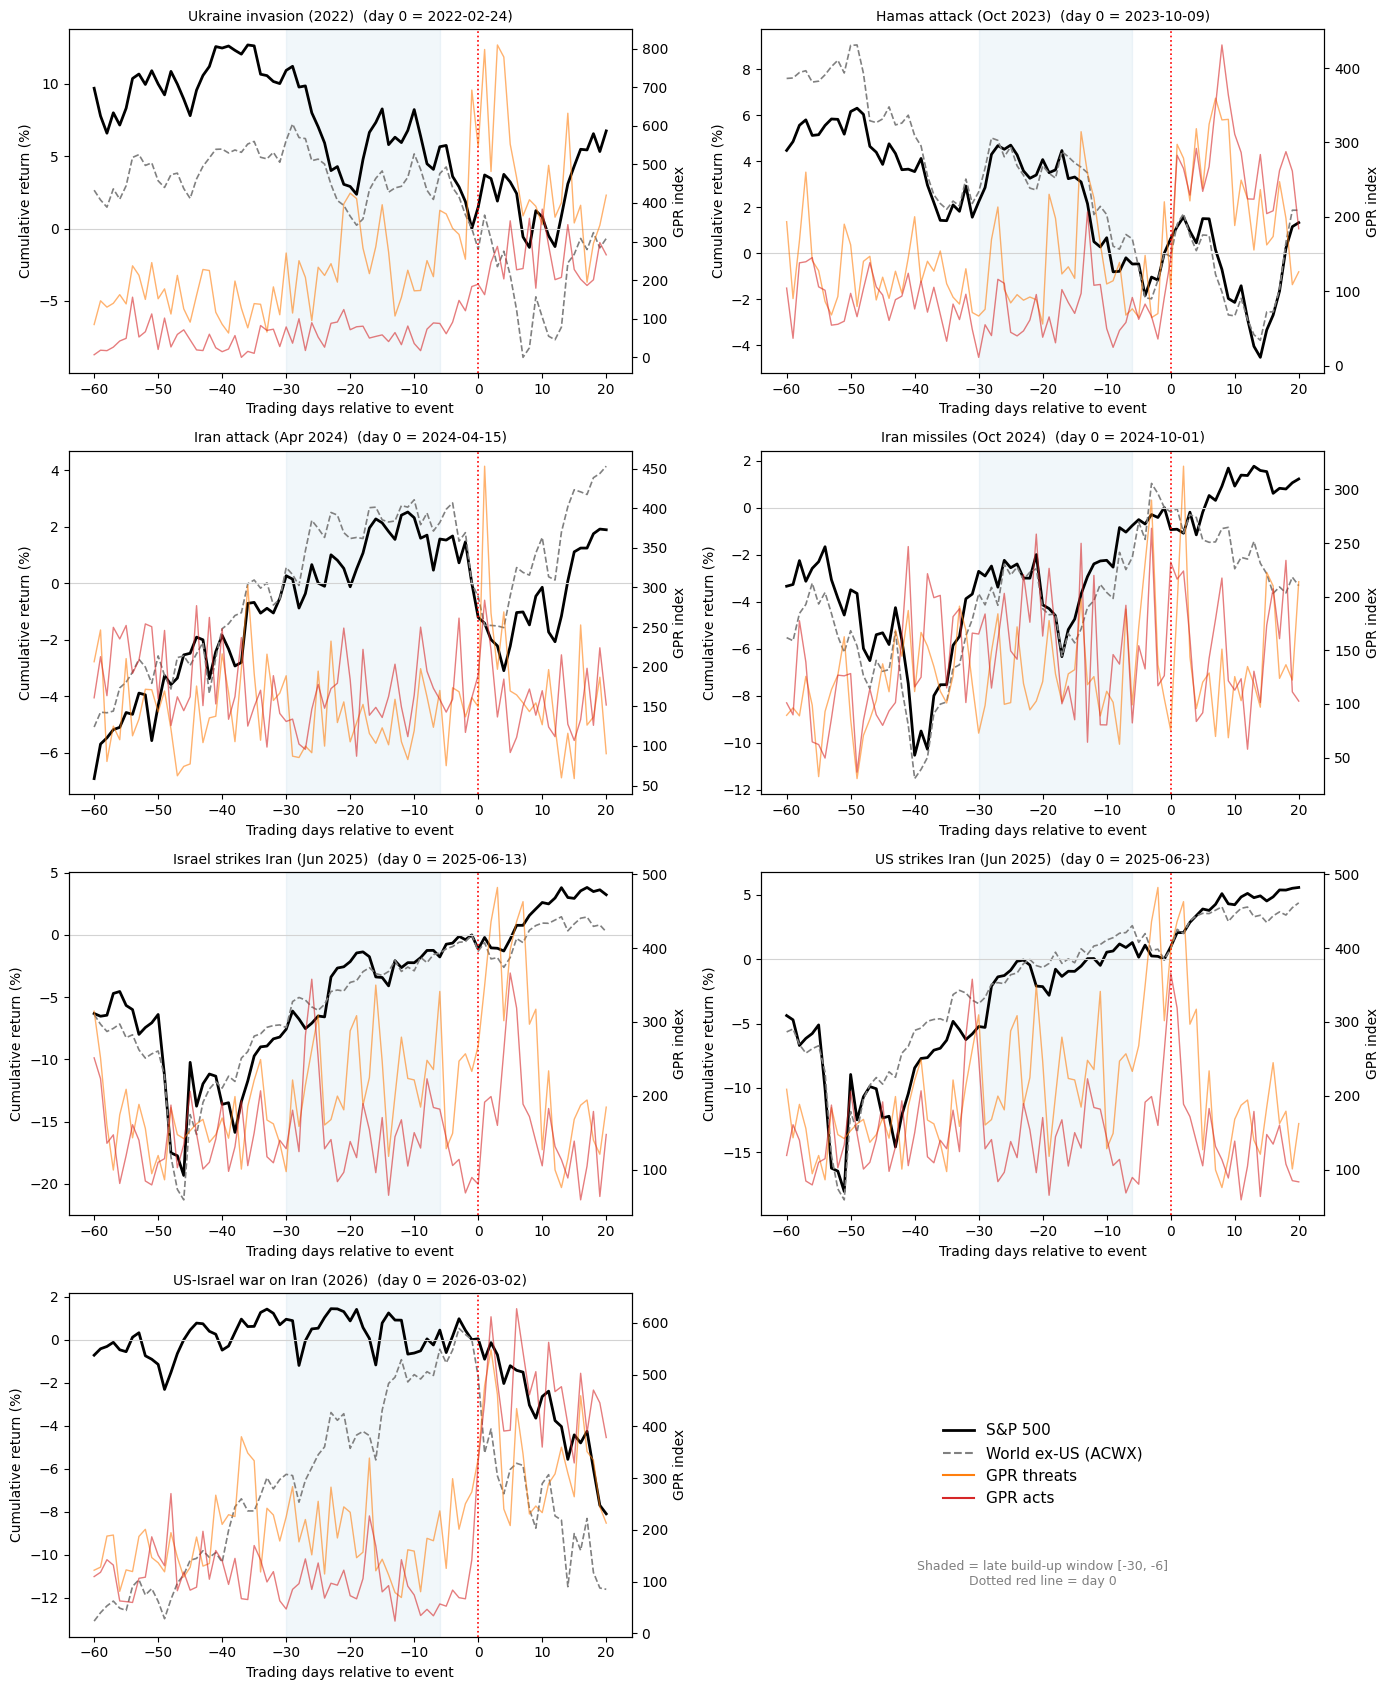

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(14, 17))
axes = axes.flatten()

for ax, (name, day0) in zip(axes, EVENTS.items()):
    w = event_window(day0)

    # left axis: cumulative returns
    ax.plot(w["t"], cum_from_day_minus1(w, "RET_GSPC"), color="black", lw=2, label="S&P 500")
    ax.plot(w["t"], cum_from_day_minus1(w, "RET_ACWX"), color="grey", lw=1.2, ls="--", label="World ex-US (ACWX)")
    ax.axhline(0, color="lightgrey", lw=0.8)
    ax.set_ylabel("Cumulative return (%)")

    # right axis: GPR threats and acts
    ax2 = ax.twinx()
    ax2.plot(w["t"], w["GPRD_THREAT"], color="tab:orange", alpha=0.6, lw=1, label="GPR threats")
    ax2.plot(w["t"], w["GPRD_ACT"], color="tab:red", alpha=0.6, lw=1, label="GPR acts")
    ax2.set_ylabel("GPR index")

    ax.axvline(0, color="red", ls=":", lw=1.2)
    ax.axvspan(-30, -6, color="tab:blue", alpha=0.06)   # late build-up window
    ax.set_title(f"{name}  (day 0 = {day0})", fontsize=10)
    ax.set_xlabel("Trading days relative to event")

# one shared legend in the empty last panel
axes[-1].axis("off")
h1, l1 = axes[0].get_legend_handles_labels()
h2, l2 = axes[0].get_shared_x_axes().get_siblings(axes[0])[0].get_legend_handles_labels()
lines = [plt.Line2D([], [], color="black", lw=2), plt.Line2D([], [], color="grey", ls="--"),
         plt.Line2D([], [], color="tab:orange"), plt.Line2D([], [], color="tab:red")]
axes[-1].legend(lines, ["S&P 500", "World ex-US (ACWX)", "GPR threats", "GPR acts"],
                loc="center", fontsize=11, frameon=False)
axes[-1].text(0.5, 0.15, "Shaded = late build-up window [-30, -6]\nDotted red line = day 0",
              ha="center", transform=axes[-1].transAxes, fontsize=9, color="grey")

plt.tight_layout()
plt.savefig(FIGS / "01_events_spx_gpr.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
WINDOWS = {
    "early_buildup [-60,-31]": (-60, -31),
    "late_buildup [-30,-6]":   (-30, -6),
    "onset [0,+1]":            (0, 1),
    "post [0,+5]":             (0, 5),
    "post [0,+10]":            (0, 10),
}

rows = []
for name, day0 in EVENTS.items():
    w = event_window(day0, pre=250, post=20)
    row = {"event": name, "day0": day0}
    for wname, (a, b) in WINDOWS.items():
        sel = w[(w["t"] >= a) & (w["t"] <= b)]
        row[f"SPX {wname}"] = sel["RET_GSPC"].sum()
        row[f"ACWX {wname}"] = sel["RET_ACWX"].sum()

    # rough "how expected was it?" measure:
    # average GPR threats in [-20,-6] relative to a normal period [-250,-61]
    pre = w[(w["t"] >= -20) & (w["t"] <= -6)]["GPRD_THREAT"].mean()
    normal = w[(w["t"] >= -250) & (w["t"] <= -61)]["GPRD_THREAT"].mean()
    row["threat_buildup_ratio"] = pre / normal
    rows.append(row)

summary = pd.DataFrame(rows).set_index("event")

# compact view: S&P 500 only
spx_cols = [c for c in summary.columns if c.startswith("SPX")] + ["threat_buildup_ratio"]
display(summary[spx_cols].round(2))

summary.to_csv(PROCESSED / "event_raw_returns.csv")
print("Saved", PROCESSED / "event_raw_returns.csv")

,"SPX early_buildup [-60,-31]","SPX late_buildup [-30,-6]","SPX onset [0,+1]","SPX post [0,+5]","SPX post [0,+10]",threat_buildup_ratio
event,,,,,,
Ukraine invasion (2022),1.63,-4.36,3.70,3.21,0.80,2.48
Hamas attack (Oct 2023),-3.01,-2.04,1.15,1.50,-2.15,1.14
Iran attack (Apr 2024),7.26,2.10,-1.42,-2.23,-0.14,0.90
Iran missiles (Oct 2024),-0.23,2.92,-0.92,-0.20,0.91,0.82
Israel strikes Iran (Jun 2025),-0.82,6.44,-0.20,-0.33,2.61,1.76
US strikes Iran (Jun 2025),-2.55,7.09,2.06,3.90,4.23,1.57
US-Israel war on Iran (2026),1.66,-0.25,-0.91,-1.21,-2.64,0.87


Saved /Users/abrar/war-puzzle-revisited/data/processed/event_raw_returns.csv
